# H1 robustness: passages over the context

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

from fsr.h1_results import (
    answer_intervals,
    load_axis,
    load_overflow,
    load_rescores,
    overflow_summary,
    rescored_table,
    score_intervals,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "grid.linewidth": 0.6,
        "grid.alpha": 0.45,
        "axes.edgecolor": "0.3",
        "axes.linewidth": 0.9,
    }
)

BAR_EDGE = sns.color_palette("muted")[0]
BAND = "0.86"
RESCORED = sns.color_palette("BuPu", 7)[5]

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_ROOT = ROOT / "data" / "nq"
FIG_DIR = ROOT / "notebooks" / "h1" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    """Write the figure as a vector PDF for the thesis and a PNG to read."""
    fig.tight_layout()
    for suffix in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{suffix}", bbox_inches="tight")


MODE = "with_body"
SPLIT = "test"

overflow = load_overflow(DATA_ROOT, SPLIT)
rescores = load_rescores(DATA_ROOT, SPLIT)
cross = load_axis(DATA_ROOT, SPLIT, "cross", MODE)
within = load_axis(DATA_ROOT, SPLIT, "within", MODE)

print(f"models re-scored: {len(rescores)} of {len(cross)}   split: {SPLIT}")

models re-scored: 6 of 6   split: test


## Passages over the context

Each candidate of each answer-axis query is rendered in all five formats and
tokenized as a query and passage pair. A record or query counts once if any of
its renderings exceeds the context.

In [2]:
summary = overflow_summary(overflow)
summary.round(2)

,renderings_over_pct,excess_median,excess_max,records,queries
model,,,,,
MiniLM-L6,0.04,4.0,12,6,22
MiniLM-L12,0.04,4.0,12,6,22
bge-base,1.44,18.0,79,47,294
bge-v2-m3,1.44,18.0,79,47,294
mxbai-v1,0.00,6.0,6,1,1
jina-v2,1.44,18.0,79,47,294


## Re-scoring

In [3]:
table = rescored_table(cross, within, overflow, rescores)
table = table.join(
    score_intervals(cross)[["low", "high"]].add_prefix("max_abs_d_orig_")
).join(answer_intervals(within)[["low", "high"]].add_prefix("inconsistency_orig_"))
table[
    [
        "records_rescored",
        "max_abs_d",
        "max_abs_d_rescored",
        "queries_rescored",
        "inconsistency_pct",
        "inconsistency_pct_rescored",
        "control_max_abs_diff",
    ]
].round(
    {
        "max_abs_d": 3,
        "max_abs_d_rescored": 3,
        "inconsistency_pct": 2,
        "inconsistency_pct_rescored": 2,
    }
)

,records_rescored,max_abs_d,max_abs_d_rescored,queries_rescored,inconsistency_pct,inconsistency_pct_rescored,control_max_abs_diff
model,,,,,,,
MiniLM-L6,6,0.903,0.903,22,14.39,14.39,0.000006
MiniLM-L12,6,0.938,0.941,22,11.94,11.94,0.000004
bge-base,47,0.383,0.370,294,17.67,17.75,0.000009
bge-v2-m3,47,0.452,0.455,294,4.66,4.52,0.000006
mxbai-v1,1,0.651,0.650,1,3.75,3.75,0.000006
jina-v2,47,0.896,0.901,294,4.90,4.90,0.000002


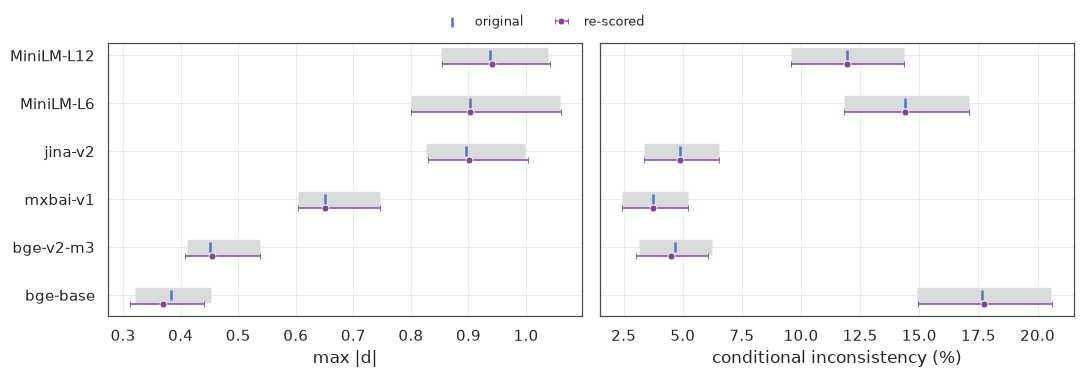

In [ ]:
order = table.sort_values("max_abs_d", ascending=False).index
panels_spec = (
    ("max_abs_d", "max_abs_d_rescored", "max |d|"),
    (
        "inconsistency_pct",
        "inconsistency_pct_rescored",
        "conditional inconsistency (%)",
    ),
)
OFFSET = 0.18

fig, panels = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (column, rescored, label) in zip(panels, panels_spec, strict=True):
    prefix = "max_abs_d" if column == "max_abs_d" else "inconsistency"
    rows = table.loc[order]
    y = list(range(len(order)))
    ax.hlines(
        y,
        rows[f"{prefix}_orig_low"],
        rows[f"{prefix}_orig_high"],
        color=BAND,
        lw=11,
        zorder=1,
    )
    ax.scatter(
        rows[column],
        y,
        s=46,
        marker="|",
        color=BAR_EDGE,
        linewidth=1.8,
        zorder=4,
        label="original",
    )
    shifted = [value + OFFSET for value in y]
    ax.errorbar(
        rows[rescored],
        shifted,
        xerr=[
            rows[rescored] - rows[f"{prefix}_low"],
            rows[f"{prefix}_high"] - rows[rescored],
        ],
        fmt="o",
        markersize=5,
        color=RESCORED,
        markeredgecolor="white",
        markeredgewidth=0.6,
        elinewidth=1.1,
        capsize=2,
        zorder=5,
        label="re-scored",
    )
    ax.set_yticks(y, order)
    ax.set_xlabel(label)
panels[0].invert_yaxis()
handles, labels = panels[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False,
    fontsize=9,
    bbox_to_anchor=(0.5, 1.06),
)
save(fig, "truncation_rescore")


## Findings

The overflow is confined to the three models that share the XLM-RoBERTa
tokenizer. 1.44% of their candidate renderings exceed the context, by a median
of 18 tokens and at most 79, and those renderings fall in 47 of the 770
records and 294 of the 767 queries. The other three models overflow on 0.04%
of renderings or fewer.

Scoring those passages again in full leaves both axes where they were. Max |d|
moves by at most 0.013 (bge-base, 0.383 to 0.370) and conditional
inconsistency by at most 0.14 points (bge-v2-m3, 4.66% to 4.52%), each inside
the original interval. The control records match the original run to within
1e-5 on every model, so the change comes from the refitted passages alone.